# Explore the interim tables

Runs after `mammo flatten`, before `features/build_train_set.py` is written.

In [1]:
import sys
print(sys.executable)      # should end in .../hackaton_mamography_ignorance/.venv/bin/python

/Users/alex/Projects_py/hackathons/prague_2026/hackaton_mamography_ignorance/.venv/bin/python


In [2]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd

from mammography.io import read_table

patients = read_table("interim", "patients", parse_dates=["birth_date", "deceased_date"])
patients.shape

(49, 15)

## 1. Patient stats

How many patients there are, whether ids are unique, and which columns are
populated enough to be features.

In [4]:
print(f"rows: {len(patients)}")
print(f"unique patient_id: {patients['patient_id'].nunique()}")
print(f"deceased: {patients['deceased_date'].notna().sum()}")
print("\nnull rate per column:")
print(patients.isna().mean().sort_values(ascending=False).to_string())

rows: 49
unique patient_id: 49
deceased: 9

null rate per column:
district              0.979592
deceased_date         0.816327
postal_code           0.306122
state                 0.020408
country               0.020408
marital_status        0.020408
preferred_language    0.020408
patient_id            0.000000
birth_date            0.000000
gender                0.000000
city                  0.000000
has_phone             0.000000
has_mobile            0.000000
has_email             0.000000
has_registered_gp     0.000000


### Age and the screening-eligible cohort

Only part of the population is ever invited. The eligible count is the real
sample size for the model — not the row count above.

gender
female    49

age: min=30 median=57.0 max=115
eligible (female, 45-69, alive): 24 of 49


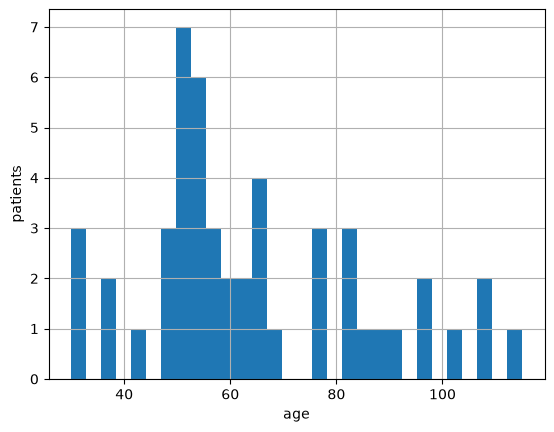

In [5]:
today = pd.Timestamp("today").normalize()
patients["age"] = ((today - patients["birth_date"]).dt.days / 365.25).astype(int)

eligible = patients[
    (patients["gender"] == "female")
    & patients["age"].between(45, 69)
    & patients["deceased_date"].isna()
]

print(patients["gender"].value_counts(dropna=False).to_string())
print(f"\nage: min={patients['age'].min()} median={patients['age'].median()} max={patients['age'].max()}")
print(f"eligible (female, 45-69, alive): {len(eligible)} of {len(patients)}")

patients["age"].hist(bins=30)
plt.xlabel("age")
plt.ylabel("patients")
plt.show()

### Geography

Candidate for the `region` feature — check the cardinality and the rare tail
before using it.

In [6]:
for column in ["state", "district", "city"]:
    counts = patients[column].value_counts(dropna=False)
    print(f"{column}: {counts.size} distinct")
    print(counts.head(10).to_string())
    print()

state: 2 distinct
state
MA     48
NaN     1

district: 2 distinct
district
NaN      48
Praha     1

city: 31 distinct
city
Worcester     4
Boston        4
Brockton      4
Lowell        3
Haverhill     2
Lynn          2
Holyoke       2
Quincy        2
Burlington    2
Plymouth      2



### Contactability

Which channels are even possible. A patient with no contact method at all is a
hard constraint on any intervention, and a channel nobody has on file cannot be
part of the recommendation — `has_mobile` in particular is expected to be mostly
False in the Synthea data, which would rule out an SMS story.

In [7]:
channels = ["has_phone", "has_mobile", "has_email", "has_registered_gp"]

print("share available:")
print(
    pd.DataFrame(
        {"all": patients[channels].mean(), "eligible": eligible[channels].mean()}
    ).to_string()
)

reachable = patients[["has_phone", "has_mobile", "has_email"]].any(axis=1)
print(f"\nno contact channel at all: {(~reachable).sum()} of {len(patients)}")

share available:
                        all  eligible
has_phone          0.979592  0.958333
has_mobile         0.000000  0.000000
has_email          0.000000  0.000000
has_registered_gp  0.000000  0.000000

no contact channel at all: 1 of 49


### Demographic candidates

A feature with one dominant value carries no information — check before adding
either of these to `training_features`.

In [8]:
for column in ["marital_status", "preferred_language"]:
    counts = patients[column].value_counts(dropna=False)
    print(f"{column}: {counts.size} distinct")
    print(counts.to_string())
    print()

marital_status: 3 distinct
marital_status
M      34
S      14
NaN     1

preferred_language: 5 distinct
preferred_language
en-US    41
es        4
hi        2
NaN       1
vi        1



## 2. Days from invitation to mammography

Decides `attendance_window_days` for the label. Every invitation is paired with
every later appointment of the same patient on purpose — the point is the shape
of the delay distribution, not a matched join. Read the cutoff off the plot:
where the bulk ends, the rest is attendance for unrelated reasons.

Needs the invitation layer, which the Synthea sample data does not contain —
this cell fails until `communications` and `appointments` exist.

In [ ]:
comms = read_table("interim", "communications", parse_dates=["sent_date"])
appts = read_table("interim", "appointments", parse_dates=["start"])

pairs = comms[["patient_id", "sent_date"]].merge(
    appts[["patient_id", "start"]], on="patient_id", how="inner"
)
pairs["days_to_appointment"] = (pairs["start"] - pairs["sent_date"]).dt.days
after = pairs.loc[pairs["days_to_appointment"].between(0, 730), "days_to_appointment"]

after.hist(bins=73)
plt.xlabel("days from invitation to mammography")
plt.ylabel("appointments")
plt.show()

after.describe()